# New York county panel

## Goal

Reproduce the displayed results from distributed local inputs, without downloading data. Run every cell in order. Numerical statements are computed in the result cells; none are hard-coded.

## Setup

Use the project's Python environment. Start Jupyter inside this repository or set `ECONHACK_REPO` explicitly. The first cell runs `python -m econhack.cli verify` before reading data. The CLI checks source and processed manifests; tables and PNGs receive separate byte-hash receipts below. No acquisition functions or model `run()` entrypoints are called.

In [1]:
import hashlib
import importlib
import inspect
import io
import json
import os
from pathlib import Path
import subprocess
import sys

def find_repository():
    explicit = os.environ.get("ECONHACK_REPO")
    candidates = [Path(explicit).expanduser().resolve()] if explicit else [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / "src/econhack/cli.py").is_file() and (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError("Open this notebook inside the repository, or set ECONHACK_REPO to its root.")

ROOT = find_repository()
os.environ["ECONHACK_OFFLINE"] = "1"
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path.insert(0, str(ROOT / "src"))
environment = os.environ.copy()
environment["PYTHONPATH"] = str(ROOT / "src") + os.pathsep + environment.get("PYTHONPATH", "")
verification = subprocess.run(
    [sys.executable, "-m", "econhack.cli", "verify"], cwd=ROOT, env=environment,
    capture_output=True, text=True, check=True,
)
print(verification.stdout.strip())
print(f"Repository: {ROOT.name}\nPython: {sys.version.split()[0]}\nMode: local files only")

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Code, Image, Markdown, display

pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 30)
pd.set_option("display.precision", 4)
plt.rcParams.update({"figure.figsize": (10, 5), "font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.prop_cycle": plt.cycler(color=["#176b87", "#b85c38"])})
PROCESSED = ROOT / "data/processed"
TABLES = ROOT / "outputs/tables"
FIGURES = ROOT / "outputs/figures"
input_receipts = []
processed_manifest = json.loads((ROOT / "data/processed_manifest.json").read_text())

def local_file(relative):
    path = (ROOT / relative).resolve()
    if ROOT not in path.parents or not path.is_file():
        raise FileNotFoundError(f"Required local input missing: {relative}. Run the project pipeline and snapshot first.")
    return path

def receipt(path):
    relative = str(path.relative_to(ROOT))
    input_receipts.append({"path": relative, "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})

def read_csv(relative, **kwargs):
    path = local_file(relative)
    if str(path.relative_to(ROOT)).startswith("data/processed/") and str(path.relative_to(ROOT)) not in processed_manifest:
        raise ValueError(f"Processed input is not in the verified manifest: {relative}. Run cli snapshot first.")
    receipt(path)
    return pd.read_csv(path, **kwargs)

def read_json(relative):
    path = local_file(relative)
    receipt(path)
    return json.loads(path.read_text())

def show_png(name, required=True):
    path = FIGURES / f"{name}.png"
    if not path.is_file() and not required:
        display(Markdown(f"Figure `{name}.png` was not produced; consult the model status and estimability table."))
        return
    path = local_file(str(path.relative_to(ROOT)))
    receipt(path)
    display(Image(data=path.read_bytes(), format="png", embed=True, width=1000))

def show_figure(figure):
    buffer = io.BytesIO()
    figure.savefig(buffer, format="png", dpi=140, bbox_inches="tight")
    display(Image(data=buffer.getvalue(), format="png", embed=True, width=1000))

def show_source(module_name, names):
    module = importlib.import_module(module_name)
    display(Markdown(f"Source: `src/{module_name.replace('.', '/')}.py`. Functions below are displayed, not invoked."))
    for name in names:
        display(Code(inspect.getsource(getattr(module, name)), language="python"))

def show_status(name):
    statuses = read_json("outputs/model_status.json")
    display(pd.DataFrame([{key: value for key, value in statuses.get(name, {"status": "not_run"}).items()
                           if key in {"status", "reason", "n", "updated_utc", "formula", "input_mode"}}]))

Verified 38 source/extract hashes; 0 large source files omitted from distribution.
Repository: econhackathon2026
Python: 3.13.7
Mode: local files only


## Context and methods

Unit: county-year, all 62 New York counties, 2018–2023. Exposure: employer establishments in 2017 NAICS 722515 (snack/nonalcoholic beverage bars, broader than cafes). Outcome: BFS business applications, not realized formations. Both rates equal `10000 * count / population_acs5`. Lagged rates use the exact prior calendar year and its denominator. Models include county/year fixed effects and county-clustered t inference. Current/lag comparisons share complete rows. See `docs/models/panel.md`.

### Verify the county-year grid, rates, and lag alignment

In [2]:
from econhack import panel as panel_module
panel = read_csv("data/processed/panel_county_year.csv", dtype={"county_fips": str, "state_fips": str, "naics": str})
assert not panel.duplicated(["county_fips", "year"]).any()
assert len(panel) == len(panel_module.NY_COUNTIES) * len(panel_module.YEARS)
for numerator, rate in [("proxy_establishments", panel_module.CURRENT), ("business_applications", panel_module.OUTCOME)]:
    np.testing.assert_allclose(panel[rate], 10000 * panel[numerator] / panel.population_acs5, equal_nan=True)
previous = panel[["county_fips", "year", panel_module.CURRENT]].rename(columns={panel_module.CURRENT: "expected_lag"})
previous["year"] += 1
aligned = panel.merge(previous, on=["county_fips", "year"], how="left", validate="one_to_one")
np.testing.assert_allclose(aligned[panel_module.LAGGED], aligned.expected_lag, equal_nan=True)
display(panel[["county_fips", "year", "proxy_establishments", "business_applications", "population_acs5", "cbp_status", "bfs_status"]].head(12))
show_status("panel")

,county_fips,year,proxy_establishments,business_applications,population_acs5,cbp_status,bfs_status
0,36001,2018,123.0,5343.0,307426.0,observed,observed
1,36001,2019,111.0,3832.0,306968.0,observed,observed
2,36001,2020,104.0,3841.0,306165.0,observed,observed
3,36001,2021,107.0,6269.0,314679.0,observed,observed
4,36001,2022,104.0,6624.0,315041.0,observed,observed
5,36001,2023,111.0,8887.0,315374.0,observed,observed
6,36003,2018,4.0,167.0,47025.0,observed,observed
7,36003,2019,3.0,192.0,46688.0,observed,observed
8,36003,2020,3.0,177.0,46304.0,observed,observed
9,36003,2021,5.0,277.0,46654.0,observed,observed


,status,reason,updated_utc,input_mode
0,complete,"NY 62 counties, 2018–2023: 372/372 usable curr...",2026-10-20T06:11:33.433242+00:00,processed_panel_offline_replay


### Coverage and estimability precede interpretation

In [3]:
display(read_csv("outputs/tables/panel_coverage.csv"))
display(read_csv("outputs/tables/panel_acquisition.csv"))
diagnostics = read_csv("outputs/tables/panel_model_diagnostics.csv")
display(diagnostics)
coefficients = read_csv("outputs/tables/panel_coefficients.csv")
assert not coefficients.duplicated(["model", "term"]).any()
display(coefficients)

,year,expected_counties,grid_counties,complete_current,complete_comparison,cbp_status_observed,cbp_status_observed_zero,cbp_status_suppressed,...,bfs_status_invalid_denominator,population_status_observed,population_status_observed_zero,population_status_suppressed,population_status_missing,population_status_missing_row,population_status_invalid,population_status_invalid_denominator
0,2018,62,62,62,0,62,0,0,...,0,62,0,0,0,0,0,0
1,2019,62,62,62,62,62,0,0,...,0,62,0,0,0,0,0,0
2,2020,62,62,62,62,62,0,0,...,0,62,0,0,0,0,0,0
3,2021,62,62,62,62,62,0,0,...,0,62,0,0,0,0,0,0
4,2022,62,62,62,62,62,0,0,...,0,62,0,0,0,0,0,0
5,2023,62,62,62,62,62,0,0,...,0,62,0,0,0,0,0,0


,source,year,url,raw_relative_path,status,rows,reason
0,BFS annual county applications,NaN,https://www.census.gov/econ/bfs/xlsx/bfs_count...,panel/bfs_county_apps_annual.xlsx,loaded,372,NaN
1,CBP county establishments,2018.0,https://www2.census.gov/programs-surveys/cbp/d...,panel/cbp/cbp18co.zip,loaded,62,NaN
2,CBP county establishments,2019.0,https://www2.census.gov/programs-surveys/cbp/d...,panel/cbp/cbp19co.zip,loaded,62,NaN
3,CBP county establishments,2020.0,https://www2.census.gov/programs-surveys/cbp/d...,panel/cbp/cbp20co.zip,loaded,62,NaN
4,CBP county establishments,2021.0,https://www2.census.gov/programs-surveys/cbp/d...,panel/cbp/cbp21co.zip,loaded,62,NaN
5,CBP county establishments,2022.0,https://www2.census.gov/programs-surveys/cbp/d...,panel/cbp/cbp22co.zip,loaded,62,NaN
6,CBP county establishments,2023.0,https://www2.census.gov/programs-surveys/cbp/d...,panel/cbp/cbp23co.zip,loaded,62,NaN
7,ACS 5-year B01003,2018.0,https://www2.census.gov/programs-surveys/acs/s...,panel/acs/acsdt5y2018-b01003.dat,loaded,62,NaN
8,ACS 5-year B01003,2019.0,https://www2.census.gov/programs-surveys/acs/s...,panel/acs/acsdt5y2019-b01003.dat,loaded,62,NaN
9,ACS 5-year B01003,2020.0,https://www2.census.gov/programs-surveys/acs/s...,panel/acs/acsdt5y2020-b01003.dat,loaded,62,NaN


,model,nobs,counties,years,status,reason,design_rank,design_columns,...,within_sd_proxy_establishments_per_10k,r_squared,within_r_squared,rmse,condition_number,cluster_df,max_leverage,within_sd_proxy_establishments_per_10k_lag1
0,current_all_years,372,62,"2018,2019,2020,2021,2022,2023",estimated,County and year fixed effects; county-clustere...,68,68,...,0.4606,0.9699,0.0206,8.1284,214.8067,61,0.4938,NaN
1,current_matched_all_years,310,62,"2019,2020,2021,2022,2023",estimated,County and year fixed effects; county-clustere...,67,67,...,0.3746,0.9696,0.0162,8.2435,214.8938,61,0.3188,NaN
2,lag1_matched_all_years,310,62,"2019,2020,2021,2022,2023",estimated,County and year fixed effects; county-clustere...,67,67,...,NaN,0.9702,0.0333,8.1719,216.5176,61,0.5599,0.4192
3,joint_matched_all_years,310,62,"2019,2020,2021,2022,2023",estimated,County and year fixed effects; county-clustere...,68,68,...,0.3746,0.9702,0.0342,8.1679,303.6114,61,0.5638,0.4192
4,current_exclude_2020_2021,248,62,"2018,2019,2022,2023",estimated,County and year fixed effects; county-clustere...,66,66,...,0.5142,0.9692,0.0220,8.2082,216.5340,61,0.6495,NaN
5,current_matched_exclude_2020_2021,124,62,"2019,2023",estimated,County and year fixed effects; county-clustere...,64,64,...,0.3855,0.9575,0.0282,9.9010,220.5731,61,0.7239,NaN
6,lag1_matched_exclude_2020_2021,124,62,"2019,2023",estimated,County and year fixed effects; county-clustere...,64,64,...,NaN,0.9596,0.0757,9.6557,217.8476,61,0.8989,0.5682
7,joint_matched_exclude_2020_2021,124,62,"2019,2023",estimated,County and year fixed effects; county-clustere...,65,65,...,0.3855,0.9598,0.0799,9.6340,305.6407,61,0.8992,0.5682


,model,term,coefficient,std_error,p_value,ci_lower,ci_upper,nobs,county_clusters,cluster_df,covariance,outcome,county_fe,year_fe
0,current_all_years,proxy_establishments_per_10k,2.5631,1.4248,0.0770,-0.2860,5.4121,372,62,61,cluster_county,applications_per_10k,True,True
1,current_matched_all_years,proxy_establishments_per_10k,2.8309,2.9296,0.3377,-3.0271,8.6890,310,62,61,cluster_county,applications_per_10k,True,True
2,lag1_matched_all_years,proxy_establishments_per_10k_lag1,3.6219,3.0797,0.2441,-2.5364,9.7801,310,62,61,cluster_county,applications_per_10k,True,True
3,joint_matched_all_years,proxy_establishments_per_10k,0.8229,1.2435,0.5106,-1.6637,3.3094,310,62,61,cluster_county,applications_per_10k,True,True
4,joint_matched_all_years,proxy_establishments_per_10k_lag1,3.2109,2.9666,0.2834,-2.7211,9.1429,310,62,61,cluster_county,applications_per_10k,True,True
5,current_exclude_2020_2021,proxy_establishments_per_10k,2.4010,1.5946,0.1373,-0.7876,5.5897,248,62,61,cluster_county,applications_per_10k,True,True
6,current_matched_exclude_2020_2021,proxy_establishments_per_10k,4.3901,7.9873,0.5846,-11.5815,20.3617,124,62,61,cluster_county,applications_per_10k,True,True
7,lag1_matched_exclude_2020_2021,proxy_establishments_per_10k_lag1,4.8834,4.0799,0.2360,-3.2749,13.0417,124,62,61,cluster_county,applications_per_10k,True,True
8,joint_matched_exclude_2020_2021,proxy_establishments_per_10k,-2.5942,4.1985,0.5390,-10.9895,5.8012,124,62,61,cluster_county,applications_per_10k,True,True
9,joint_matched_exclude_2020_2021,proxy_establishments_per_10k_lag1,6.2233,4.4796,0.1698,-2.7342,15.1809,124,62,61,cluster_county,applications_per_10k,True,True


### Recreate aggregate rates with the paired observed county totals

,year,matched_counties,population_acs5,proxy_establishments,business_applications,proxy_establishments_per_10k,applications_per_10k
0,2018,62,19618453,5849,226804,2.9814,115.6075
1,2019,62,19572319,6110,229007,3.1218,117.0056
2,2020,62,19514849,6126,253660,3.1391,129.9831
3,2021,62,20114745,6323,309678,3.1435,153.9557
4,2022,62,19994379,6741,297758,3.3714,148.9209
5,2023,62,19872319,7169,312282,3.6075,157.1442


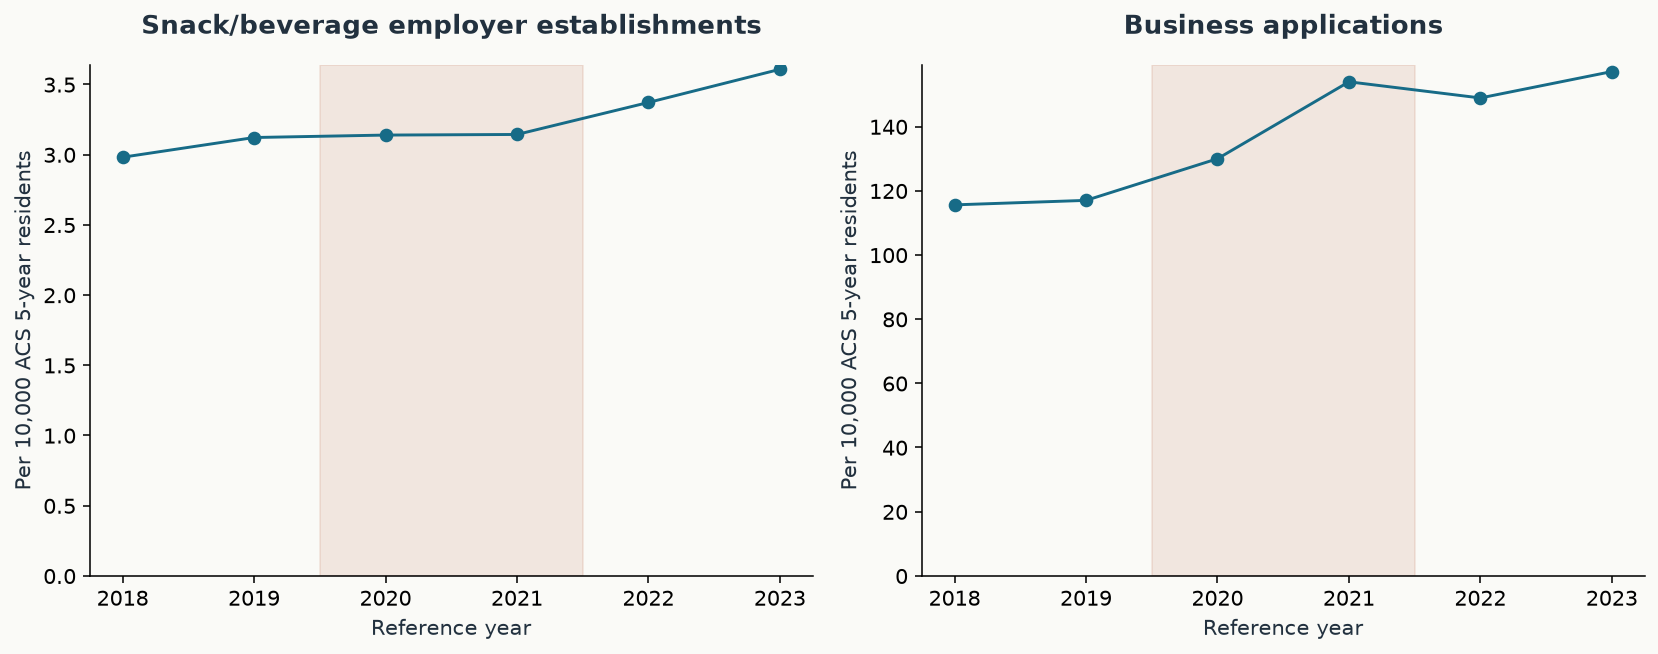

In [4]:
annual = read_csv("outputs/tables/panel_annual_summary.csv")
display(annual)
figure, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for axis, variable, label in zip(axes, [panel_module.CURRENT, panel_module.OUTCOME],
                                  ["Snack/beverage employer establishments", "Business applications"]):
    axis.plot(annual.year, annual[variable], marker="o")
    axis.axvspan(2019.5, 2021.5, alpha=0.12, color="#b85c38")
    axis.set(title=label, xlabel="Reference year", ylabel="Per 10,000 ACS 5-year residents", ylim=(0, None))
figure.tight_layout()
show_figure(figure)
plt.close(figure)

### Saved evidence and diagnostics

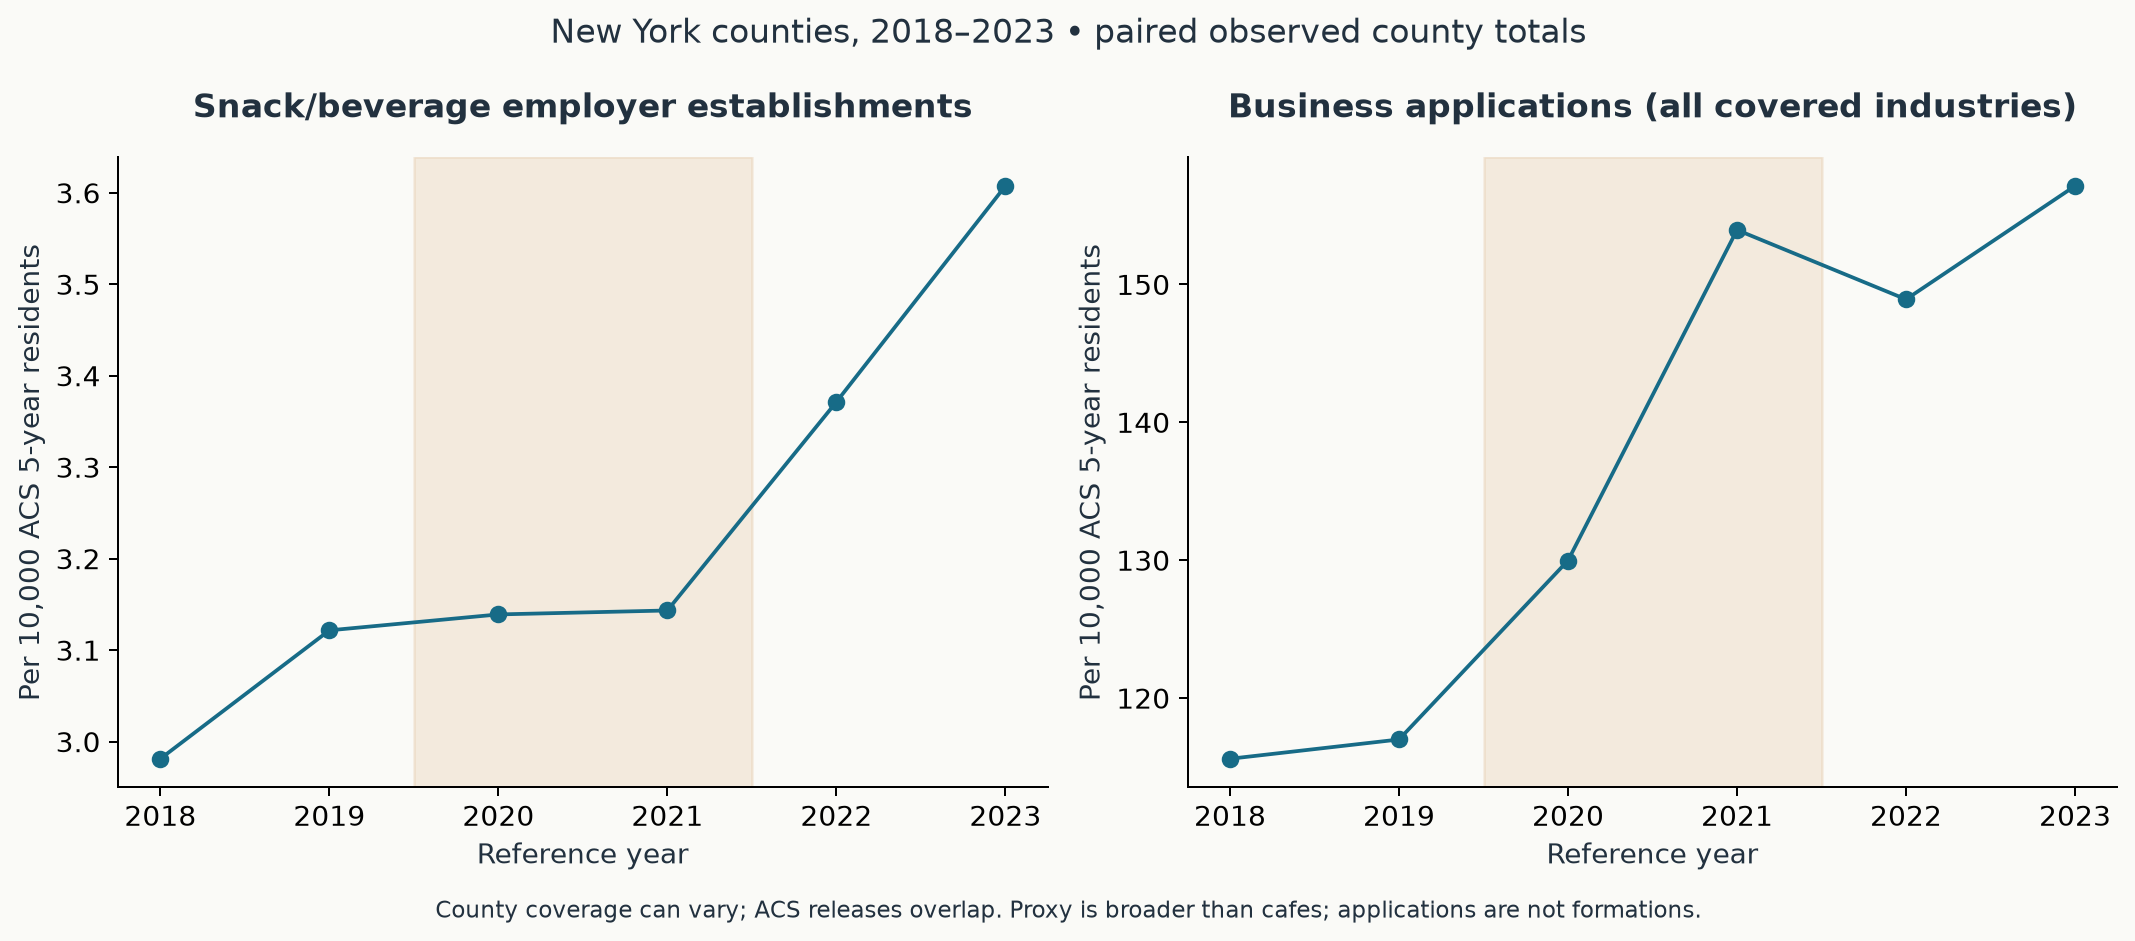

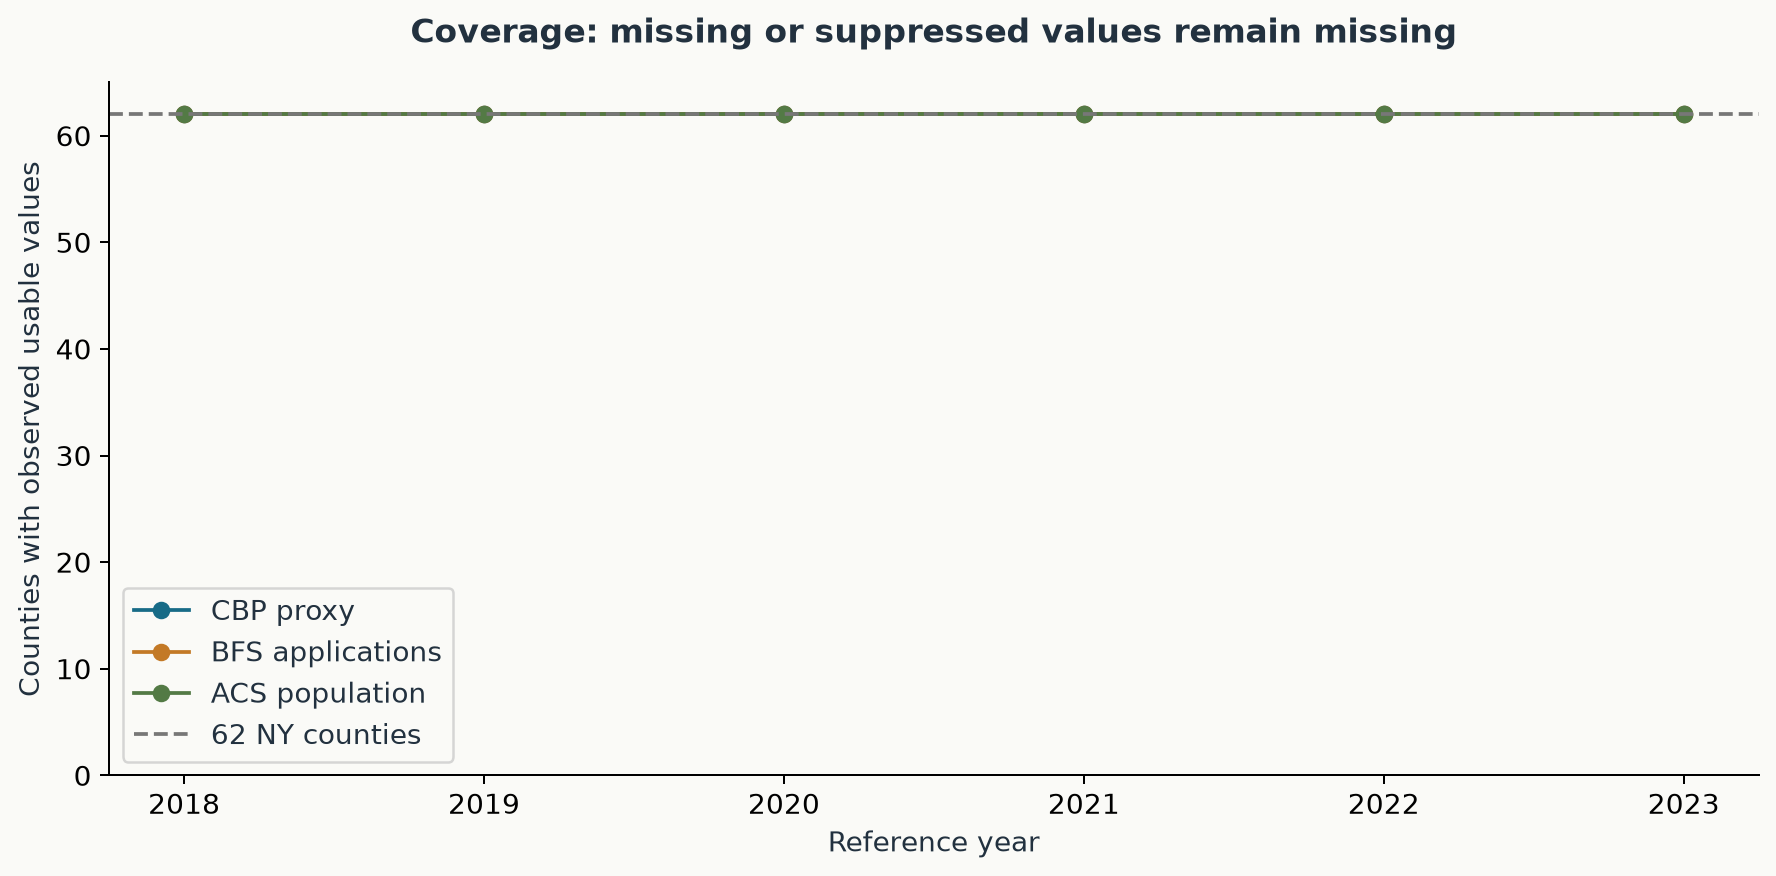

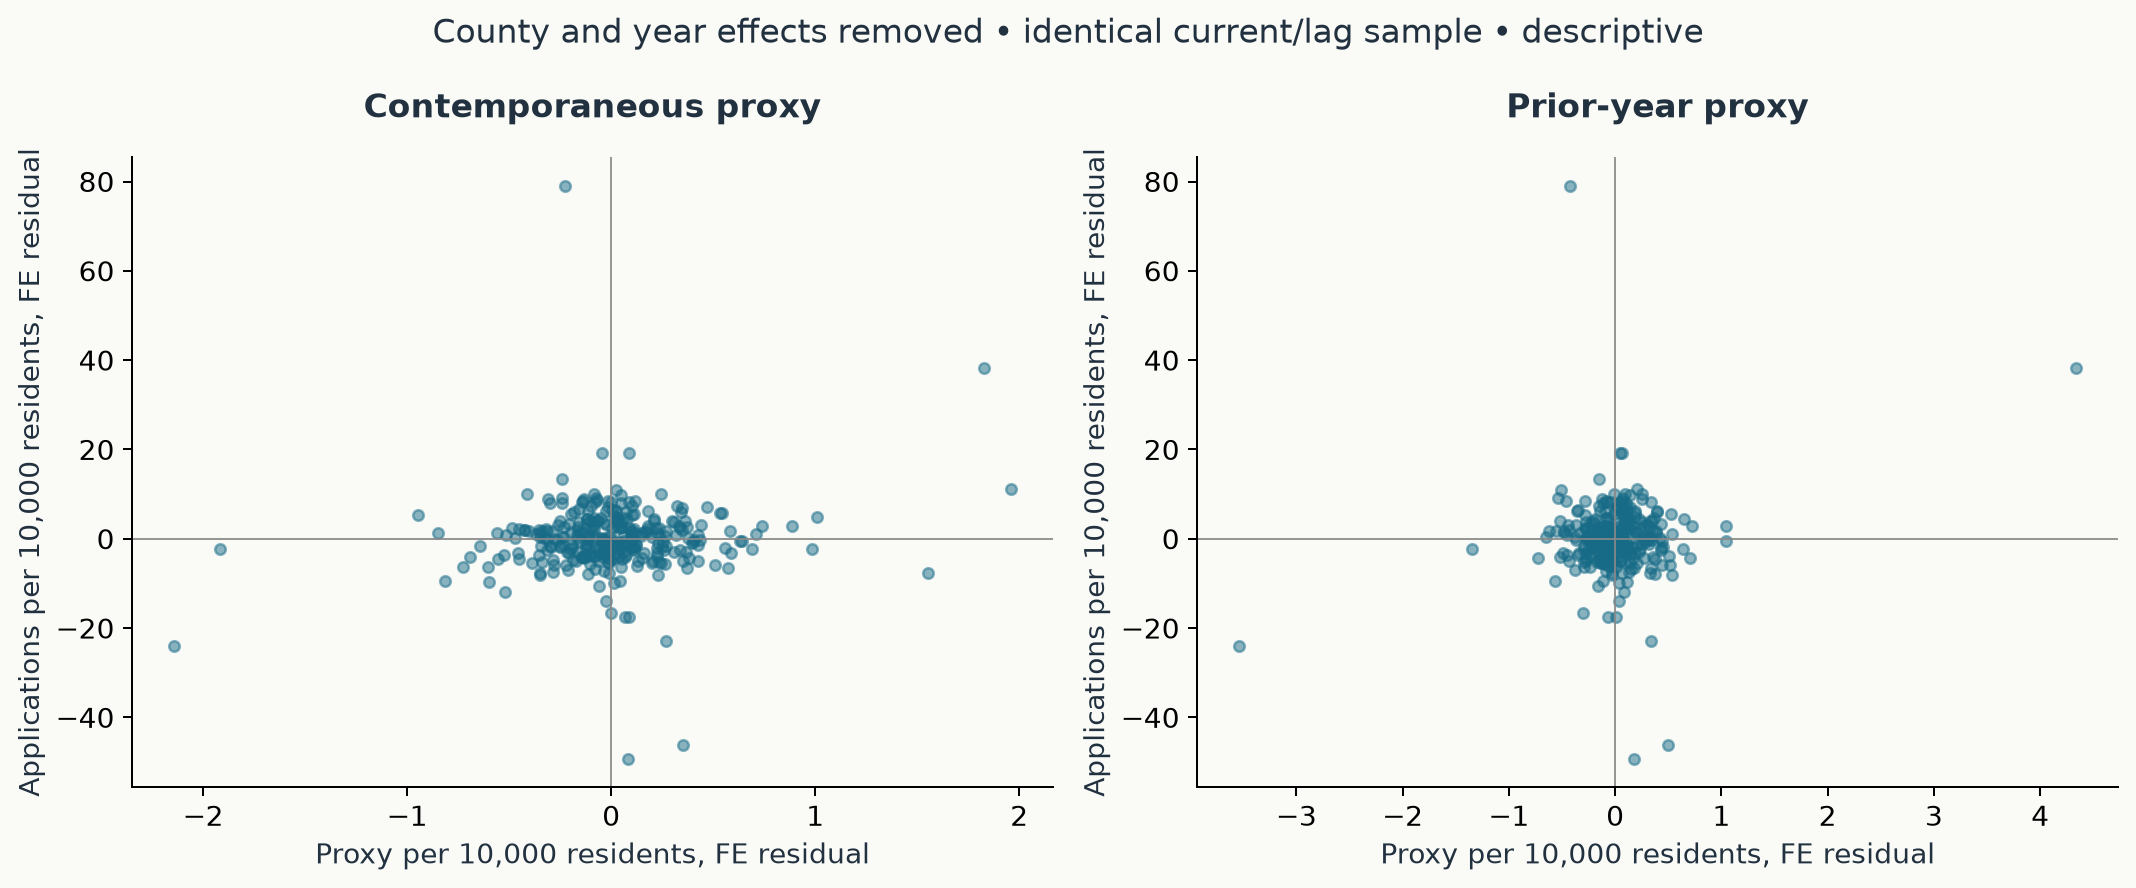

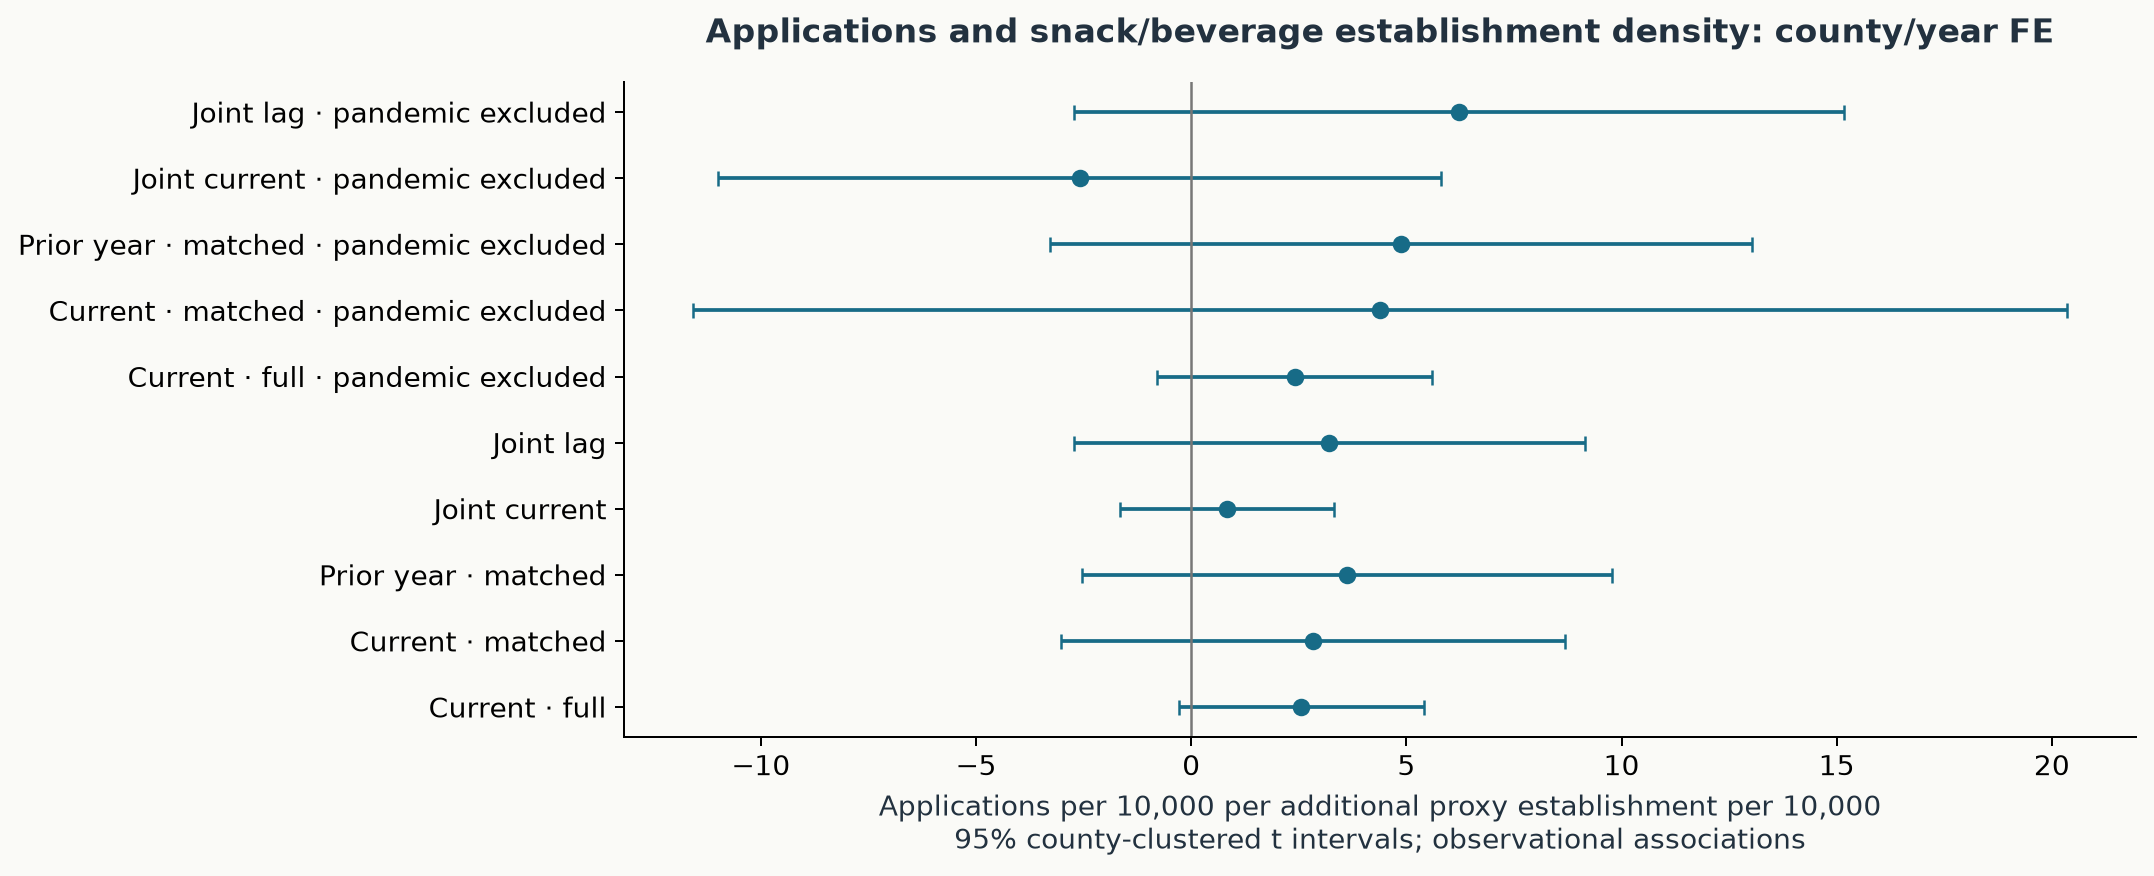

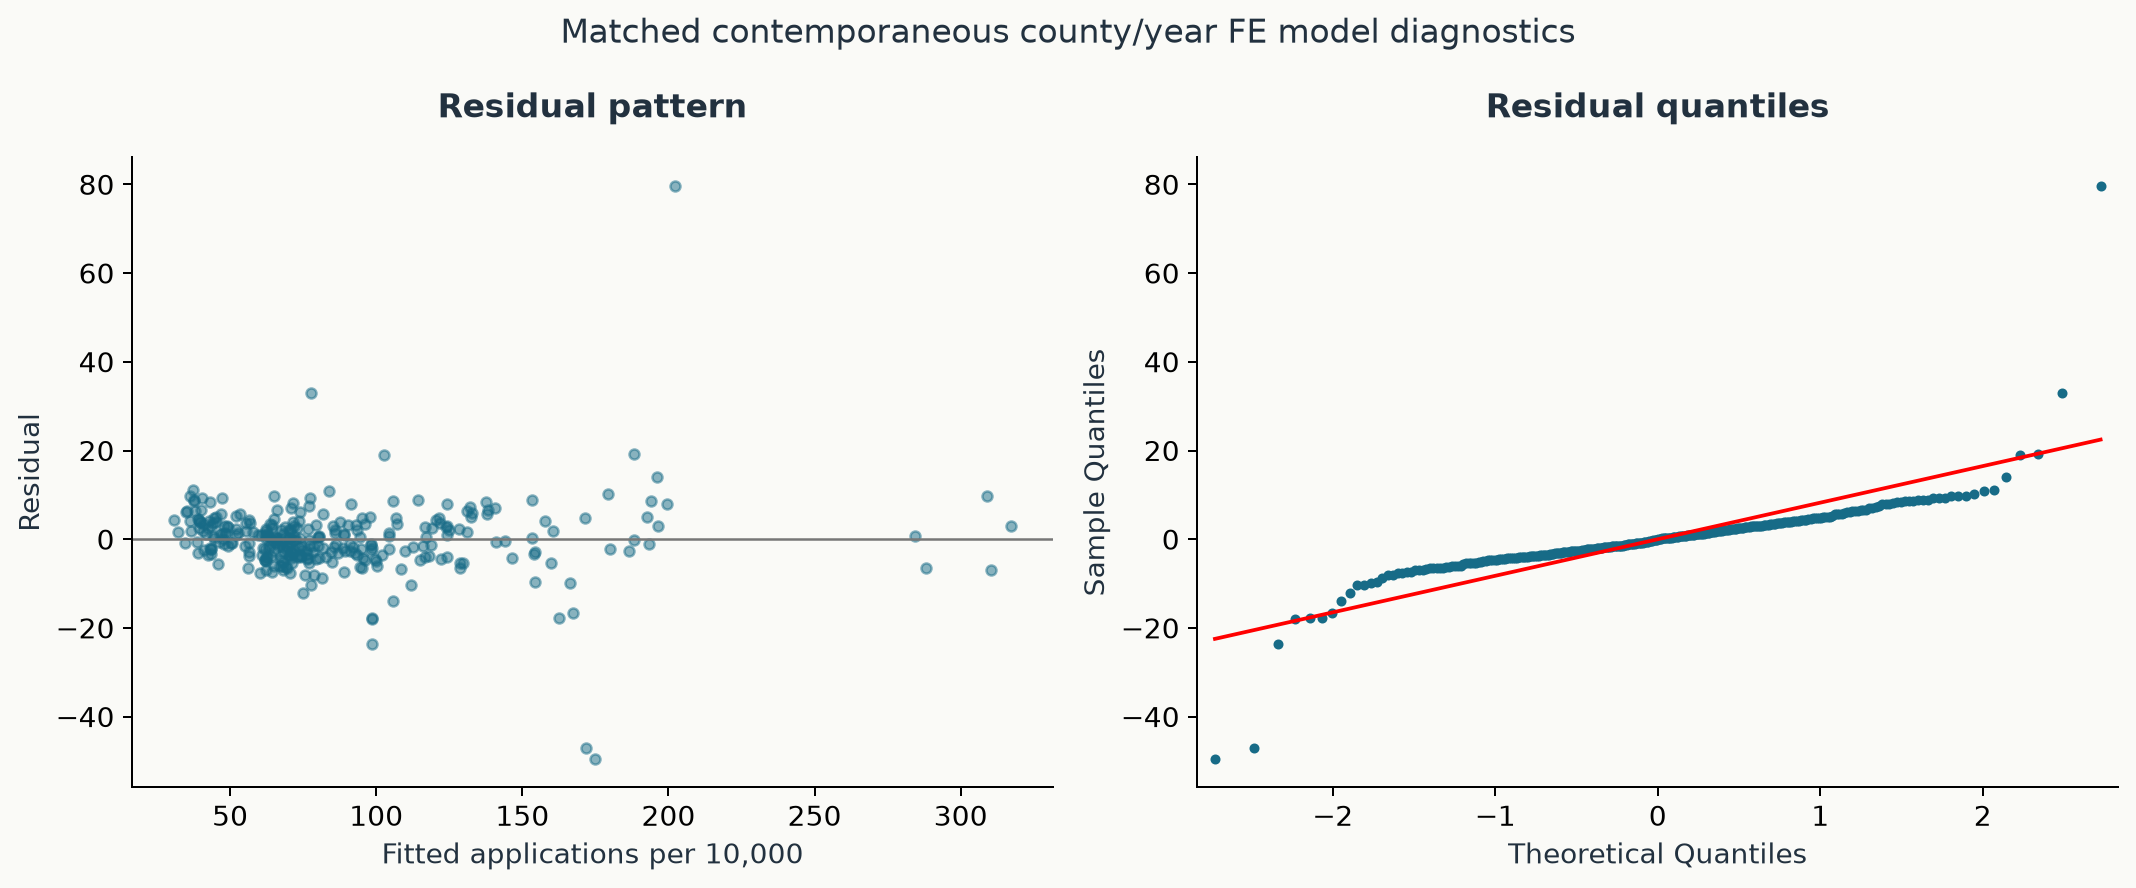

,first,second,adjustment,n_pairs,pearson,spearman,sample_covariance_ddof1
24,proxy_establishments_per_10k,applications_per_10k,pooled,372,0.4390,0.5696,35.2525
25,proxy_establishments_per_10k,applications_per_10k,county_year_residuals,372,0.1435,0.0988,0.5437
26,proxy_establishments_per_10k,proxy_establishments_per_10k_lag1,pooled,310,0.9676,0.9127,2.7260
27,proxy_establishments_per_10k,proxy_establishments_per_10k_lag1,county_year_residuals,310,0.5589,0.3271,0.0878


,model,term,other_term,cluster_covariance
0,current_all_years,proxy_establishments_per_10k,proxy_establishments_per_10k,2.0300
1,current_matched_all_years,proxy_establishments_per_10k,proxy_establishments_per_10k,8.5825
2,lag1_matched_all_years,proxy_establishments_per_10k_lag1,proxy_establishments_per_10k_lag1,9.4846
3,joint_matched_all_years,proxy_establishments_per_10k,proxy_establishments_per_10k,1.5463
4,joint_matched_all_years,proxy_establishments_per_10k,proxy_establishments_per_10k_lag1,0.1577
5,joint_matched_all_years,proxy_establishments_per_10k_lag1,proxy_establishments_per_10k,0.1577
6,joint_matched_all_years,proxy_establishments_per_10k_lag1,proxy_establishments_per_10k_lag1,8.8004
7,current_exclude_2020_2021,proxy_establishments_per_10k,proxy_establishments_per_10k,2.5428
8,current_matched_exclude_2020_2021,proxy_establishments_per_10k,proxy_establishments_per_10k,63.7970
9,lag1_matched_exclude_2020_2021,proxy_establishments_per_10k_lag1,proxy_establishments_per_10k_lag1,16.6457


In [5]:
show_png("panel_annual_trends")
show_png("panel_coverage")
show_png("panel_within_associations")
show_png("panel_coefficients", required=not coefficients.empty)
show_png("panel_residual_diagnostics", required=diagnostics.loc[diagnostics.model.eq("current_matched_all_years"), "status"].eq("estimated").any())
associations = read_csv("outputs/tables/panel_correlations_covariance.csv")
display(associations.loc[associations["first"].eq(panel_module.CURRENT)])
display(read_csv("outputs/tables/panel_coefficient_covariance.csv"))

### Inspect transformations and model specification

In [6]:
show_source("econhack.panel", ["build_panel", "model_samples", "fit_models"])

Source: `src/econhack/panel.py`. Functions below are displayed, not invoked.

def build_panel(cbp, bfs, population, years=YEARS, counties=NY_COUNTIES):
    """Retain the explicit geography-year grid; absent records never imply zero."""
    grid = pd.MultiIndex.from_product([counties, years], names=["county_fips", "year"]).to_frame(index=False)
    for data, label in [(cbp, "CBP"), (bfs, "BFS"), (population, "ACS")]:
        grid = grid.merge(_unique(data, label), on=["county_fips", "year"], how="left", validate="one_to_one")
    for name in ["cbp_status", "bfs_status", "population_status"]:
        grid[name] = grid[name].fillna("missing_row")
    grid["state_fips"] = "36"
    grid["state"] = "New York"
    grid["naics"] = NAICS
    grid["naics_vintage"] = NAICS_VINTAGE
    grid["acs_period_start"] = grid.year - 4
    grid["acs_period_end"] = grid.year
    denominator = grid.population_acs5.where(grid.population_acs5.gt(0))
    grid[CURRENT] = 10_000 * grid.proxy_establishments / denominator
    grid[OUTCOME] = 10_000 * grid.business_applications / denominator
    grid = grid.sort_values(["county_fips", "year"]).reset_index(drop=True)
    previous = grid[["county_fips", "year", CURRENT]].rename(columns={CURRENT: LAGGED})
    previous["year"] += 1
    grid = grid.merge(previous, on=["county_fips", "year"], how="left", validate="one_to_one")
    grid["lag_source_year"] = (grid.year - 1).where(grid[LAGGED].notna()).astype("Int64")
    grid["complete_current"] = grid[[OUTCOME, CURRENT]].notna().all(axis=1)
    grid["complete_comparison"] = grid[[OUTCOME, CURRENT, LAGGED]].notna().all(axis=1)
    return grid

def model_samples(panel):
    """Matched current/lag models share rows; COVID drops lag exposures too."""
    specifications = [("current", [CURRENT], [OUTCOME, CURRENT]),
                      ("current_matched", [CURRENT], [OUTCOME, CURRENT, LAGGED]),
                      ("lag1_matched", [LAGGED], [OUTCOME, CURRENT, LAGGED]),
                      ("joint_matched", [CURRENT, LAGGED], [OUTCOME, CURRENT, LAGGED])]
    for sensitivity in ["all_years", "exclude_2020_2021"]:
        for specification, predictors, required in specifications:
            data = panel.loc[np.isfinite(panel[required].astype(float)).all(axis=1)].copy()
            if sensitivity != "all_years":
                data = data.loc[~data.year.isin(COVID_YEARS)]
                if specification != "current":
                    data = data.loc[~(data.year - 1).isin(COVID_YEARS)]
            yield f"{specification}_{sensitivity}", predictors, data

def fit_models(panel):
    coefficient_rows, diagnostic_rows, covariance_rows, residual_rows, sample_rows = [], [], [], [], []
    for model, predictors, data in model_samples(panel):
        for row in data[["county_fips", "year"]].to_dict("records"):
            sample_rows.append({"model": model, **row})
        diagnostic = {"model": model, "nobs": len(data), "counties": data.county_fips.nunique(),
                      "years": ",".join(str(year) for year in sorted(data.year.unique())),
                      "status": "not_estimable", "reason": "Insufficient counties or years"}
        if diagnostic["counties"] < 2 or data.year.nunique() < 2:
            diagnostic_rows.append(diagnostic)
            continue
        effects = _fixed_effects(data)
        design = pd.concat([effects, data[predictors].astype(float)], axis=1)
        rank = int(np.linalg.matrix_rank(design))
        within = residualize(data, [OUTCOME, *predictors])
        diagnostic.update(design_rank=rank, design_columns=design.shape[1], residual_df=len(data) - rank,
                          singleton_counties=int(data.groupby("county_fips").size().eq(1).sum()))
        for predictor in predictors:
            diagnostic[f"within_sd_{predictor}"] = float(within[predictor].std())
        if rank != design.shape[1] or len(data) <= rank or within[OUTCOME].std() < 1e-10:
            diagnostic["reason"] = "Rank deficient design, no residual degrees of freedom, or no within outcome variation"
            diagnostic_rows.append(diagnostic)
            continue
        result = sm.OLS(data[OUTCOME].astype(float), design).fit(
            cov_type="cluster", cov_kwds={"groups": data.county_fips, "use_correction": True,
                                          "df_correction": True}, use_t=True)
        intervals = result.conf_int()
        finite = np.isfinite(result.bse[predictors]).all() and np.isfinite(intervals.loc[predictors]).all().all()
        diagnostic.update(status="estimated" if finite else "invalid_inference",
                          reason="County and year fixed effects; county-clustered t inference" if finite else "Nonfinite clustered inference",
                          r_squared=float(result.rsquared),
                          within_r_squared=float(1 - np.square(result.resid).sum() / np.square(within[OUTCOME]).sum()),
                          rmse=float(np.sqrt(np.mean(np.square(result.resid)))),
                          condition_number=float(result.condition_number), cluster_df=diagnostic["counties"] - 1,
                          max_leverage=float(result.get_influence().hat_matrix_diag.max()))
        diagnostic_rows.append(diagnostic)
        if not finite:
            continue
        for predictor in predictors:
            coefficient_rows.append({"model": model, "term": predictor, "coefficient": result.params[predictor],
                                     "std_error": result.bse[predictor], "p_value": result.pvalues[predictor],
                                     "ci_lower": intervals.loc[predictor, 0], "ci_upper": intervals.loc[predictor, 1],
                                     "nobs": len(data), "county_clusters": diagnostic["counties"],
                                     "cluster_df": diagnostic["counties"] - 1, "covariance": "cluster_county",
                                     "outcome": OUTCOME, "county_fe": True, "year_fe": True})
            for other in predictors:
                covariance_rows.append({"model": model, "term": predictor, "other_term": other,
                                        "cluster_covariance": result.cov_params().loc[predictor, other]})
        for position, (_, row) in enumerate(data.iterrows()):
            residual_rows.append({"model": model, "county_fips": row.county_fips, "year": row.year,
                                  "fitted": float(result.fittedvalues.iloc[position]),
                                  "residual": float(result.resid.iloc[position])})
    return {"panel_coef

## Interpretation and limits

Suppression and absent records remain missing, not zeros. Adjacent ACS 5-year denominators overlap. Shared denominators, reverse causality, time-varying confounding, geographic dependence, and measurement error remain. The sensitivity removes 2020/2021 outcomes and matched rows with 2020/2021 lag exposures; it does not remove all pandemic influence. Fixed effects and lags do not establish causality or out-of-sample predictive accuracy.

## Inputs used

Exact local inputs and SHA-256 hashes for this execution. These receipts identify table/figure versions; they are not an independent validation of their statistical content.

In [7]:
display(pd.DataFrame(input_receipts).drop_duplicates().reset_index(drop=True))

,path,sha256
0,data/processed/panel_county_year.csv,6d12d46e09fc450fbad2841668025bb931a5772a25cb15...
1,outputs/model_status.json,3325cedafcf9fe7d8ff7bab928673fdb271f379ac69b9c...
2,outputs/tables/panel_coverage.csv,b5122ba3dedc7b185769fade6970b4eb0946666a5cbb00...
3,outputs/tables/panel_acquisition.csv,ba0d4b44b5c7cb68f7d7cc4250683423f62c9a4c35c1b7...
4,outputs/tables/panel_model_diagnostics.csv,75ebe90be0a901b79426ced76615f5192be44e726d219b...
5,outputs/tables/panel_coefficients.csv,3c709904da10dd4fc60a31dc40bb69935543ac0d24968c...
6,outputs/tables/panel_annual_summary.csv,8ed5d00fb836dd9eb917068c871c5343a7e2b8b281e04c...
7,outputs/figures/panel_annual_trends.png,4209a60f30bbd9554daf1c53da261e1978e2d9ab4e5b73...
8,outputs/figures/panel_coverage.png,32f3d5600ed8bbc946322a65af378ddbb744ea76881abf...
9,outputs/figures/panel_within_associations.png,82f82054d298c1385e709541654d302cf9bec415316e5f...
